# EF110 Frequency Response

Attenuation vs. frequency from `Frequency_Response_Curve_EF110.txt`, with the interpolated -1 dB and -3 dB points marked.

In [1]:
%matplotlib widget

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
label_font = {
    "fontname": "sans-serif",
    "size": 12,
    "color": "black",
    "weight": "normal",
    "verticalalignment": "bottom",
}
title_font = {
    "fontname": "sans-serif",
    "size": 12,
    "color": "black",
    "weight": "normal",
}
legend_font = {
    "family": "sans-serif",
    "size": 12,
    "style": "normal",
    "weight": "normal",
}

In [3]:
data_file = Path("Frequency_Response_Curve_EF110.txt")

df = pd.read_csv(data_file, sep="\t")
# Drop the hand-entered interpolation rows that have no measured amplitudes
df = df.dropna(subset=["Amplitude (mV)", "Filtered Amplitude (mV)"]).reset_index(drop=True)

freq = df["Frequency (Hz)"].to_numpy(dtype=float)
amp = df["Amplitude (mV)"].to_numpy(dtype=float)
amp_filt = df["Filtered Amplitude (mV)"].to_numpy(dtype=float)

# Same sign convention as the fourth column of the file (negative = attenuated)
atten_db = 20 * np.log10(amp_filt / amp)
df["Attenuation (dB)"] = atten_db
df

,Frequency (Hz),Amplitude (mV),Filtered Amplitude (mV),Insertion Loss (dB),Attenuation (dB)
0,10.0,4932.2,4539.7000,-0.72,-0.720270
1,100.0,4932.2,4539.7000,-0.72,-0.720270
2,200.0,4932.2,4539.7000,-0.72,-0.720270
3,300.0,4932.2,4539.7000,-0.72,-0.720270
4,400.0,4966.4,4564.2000,-0.73,-0.733541
5,500.0,4966.4,4563.7000,-0.73,-0.734492
6,600.0,4932.2,4471.4000,-0.85,-0.851943
7,700.0,4932.2,4471.4000,-0.85,-0.851943
8,800.0,4932.2,4471.4000,-0.85,-0.851943
9,900.0,4932.2,4471.4000,-0.85,-0.851943


In [4]:
def crossing_frequency(freq, db, level):
    """Linearly interpolate the first frequency at which db falls through `level`."""
    below = np.nonzero(db <= level)[0]
    if len(below) == 0 or below[0] == 0:
        return None
    i = below[0]
    f0, f1 = freq[i - 1], freq[i]
    d0, d1 = db[i - 1], db[i]
    return f0 + (level - d0) * (f1 - f0) / (d1 - d0)


f_1db = crossing_frequency(freq, atten_db, -1.0)
f_3db = crossing_frequency(freq, atten_db, -3.0)
print(f"-1 dB point: {f_1db:.2f} Hz")
print(f"-3 dB point: {f_3db:.2f} Hz")

-1 dB point: 1016.27 Hz
-3 dB point: 1414.15 Hz


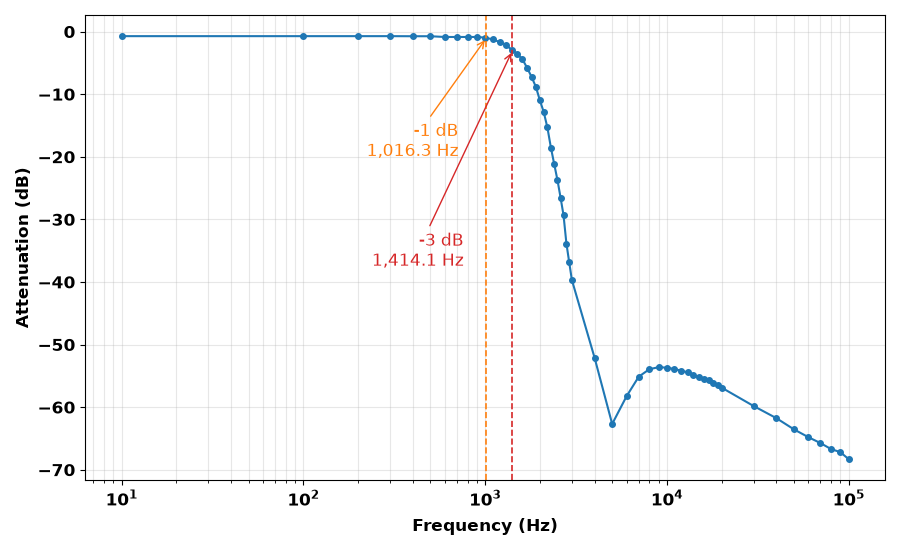

In [11]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(freq, atten_db, "o-", color="tab:blue", markersize=4, label="EF110 response")

# (frequency, level, color, annotation text offset in points)
markers = [(f_1db, -1.0, "tab:orange", (-20, -60)), (f_3db, -3.0, "tab:red", (-35, -130))]
for f_c, level, color, text_offset in markers:
    if f_c is None:
        continue
    ax.axvline(f_c, color=color, linestyle="--", linewidth=1.2,
               label=f"{level:g} dB @ {f_c:,.1f} Hz")
    ax.annotate(
        f"{level:g} dB\n{f_c:,.1f} Hz",
        xy=(f_c, level),
        xytext=text_offset,
        textcoords="offset points",
        horizontalalignment="right",
        arrowprops=dict(arrowstyle="->", color=color),
        **{**label_font, "color": color, "verticalalignment": "top"},
    )

axis_label_font = {**label_font, "weight": "bold"}

ax.set_xscale("log")
ax.set_xlabel("Frequency (Hz)", labelpad=18, **axis_label_font)
ax.set_ylabel("Attenuation (dB)", labelpad=4, **axis_label_font)
#ax.set_title("EF110 Frequency Response", **title_font)
ax.tick_params(which="both", labelsize=label_font["size"])
# New ticks created on zoom/pan copy these font properties, so bold persists
for tick_label in (ax.get_xticklabels(which="both") + ax.get_yticklabels(which="both")):
    tick_label.set_fontweight("bold")
ax.grid(True, which="both", alpha=0.3)
#ax.legend(prop=legend_font, loc="lower left")
fig.tight_layout()
plt.show()